# TMG Vietnamese Intent Classification — Research & Production Notebook

This notebook refactors the monolithic `tmg_intent_classification_pipeline.py` into a sequential, auditable experiment pipeline for the localized CLINC150 subset.

**Task:** 20 supported Vietnamese banking/card intents + `out_of_scope`.

**Experimental progression:** frozen PhoBERT + classifier (baseline) → fine-tuned PhoBERT (proposed) → validation-only OOS thresholding → temperature scaling → imbalance/augmentation ablations → robustness evaluation → artifact export and latency.

The notebook keeps the test split untouched for final reporting. Thresholds and temperature are learned only from validation data. The current dataset is treated as an input artifact; no missing translations or unresolved semantic label conflicts are silently invented.

## Section 1 — Environment Setup & Dependencies Check
### Step 1 — Reproducible environment

Purpose: establish the packages required by the data, classical ML, Vietnamese preprocessing, PyTorch, and Transformer stages. The cell installs only packages that are missing, then verifies versions. GPU availability is reported but not assumed.

In [1]:
import sys, subprocess, importlib.util, platform

REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "torch": "torch",
    "transformers": "transformers",
    "underthesea": "underthesea",
    "joblib": "joblib",
    "nbformat": "nbformat",
}

missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import numpy as np
import pandas as pd
import sklearn
import torch
import transformers
import underthesea
import joblib

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("underthesea:", underthesea.__version__ if hasattr(underthesea, "__version__") else "installed")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
PyTorch: 2.11.0+cu130
Transformers: 5.22.0
underthesea: 9.5.0
CUDA available: True
GPU: Tesla T4


### Step 2 — Experiment configuration and reproducibility contract

Purpose: freeze the experimental constants before model training. All models share the same dataset membership, label mapping, evaluation protocol, and seed unless an explicit ablation changes one factor.

In [2]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from dataclasses import dataclass, asdict
from pathlib import Path
import json, math, os, random, re, time, unicodedata, copy
from typing import Dict, List, Sequence, Tuple, Optional


@dataclass
class Config:
    data_path: str = "/content/drive/MyDrive/clinc20_vi/subset20_vi_v2.json"
    output_dir: str = "artifacts_notebook"
    model_name: str = "vinai/phobert-base-v2"
    max_length: int = 96
    seed: int = 42
    train_batch_size: int = 16
    eval_batch_size: int = 32
    epochs: int = 4
    learning_rate: float = 2e-5
    frozen_learning_rate: float = 1e-3
    frozen_epochs: int = 12
    frozen_pooling: str = "mean"  # "mean" or "cls"; only used by the frozen baseline
    weight_decay: float = 0.01
    warmup_ratio: float = 0.10
    gradient_clip_norm: float = 1.0
    dropout: float = 0.10
    use_class_weights: bool = False
    use_train_augmentation: bool = True
    augmentation_probability: float = 0.25
    threshold_grid_start: float = 0.05
    threshold_grid_stop: float = 0.995
    threshold_grid_steps: int = 190
    temperature_min: float = 0.25
    temperature_max: float = 5.0
    temperature_steps: int = 191
    num_workers: int = 0
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

CFG = Config()
OUT = Path(CFG.output_dir)
OUT.mkdir(parents=True, exist_ok=True)

SUPPORTED_SPLITS = ("train", "val", "test", "oos_train", "oos_val", "oos_test")
IN_SCOPE_SPLITS = ("train", "val", "test")
OOS_SPLITS = ("oos_train", "oos_val", "oos_test")
OOS_LABEL = "out_of_scope"
EXPECTED_INTENTS = {
    "account_blocked", "balance", "bill_balance", "bill_due", "freeze_account",
    "interest_rate", "min_payment", "pay_bill", "pin_change", "report_fraud",
    "spending_history", "transactions", "transfer", "card_declined", "credit_limit",
    "credit_score", "expiration_date", "international_fees", "new_card", "report_lost_card",
}


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.seed)
print(json.dumps(asdict(CFG), indent=2, ensure_ascii=False))

{
  "data_path": "/content/drive/MyDrive/clinc20_vi/subset20_vi_v2.json",
  "output_dir": "artifacts_notebook",
  "model_name": "vinai/phobert-base-v2",
  "max_length": 96,
  "seed": 42,
  "train_batch_size": 16,
  "eval_batch_size": 32,
  "epochs": 4,
  "learning_rate": 2e-05,
  "frozen_learning_rate": 0.001,
  "frozen_epochs": 12,
  "frozen_pooling": "mean",
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "gradient_clip_norm": 1.0,
  "dropout": 0.1,
  "use_class_weights": false,
  "use_train_augmentation": true,
  "augmentation_probability": 0.25,
  "threshold_grid_start": 0.05,
  "threshold_grid_stop": 0.995,
  "threshold_grid_steps": 190,
  "temperature_min": 0.25,
  "temperature_max": 5.0,
  "temperature_steps": 191,
  "num_workers": 0,
  "device": "cuda"
}


## Section 2 — Data Loading & Schema Validation
### Step 3 — Load the localized dataset

Purpose: load the exported JSON produced by the localization pipeline without altering its split membership. Expected format is a dictionary containing `train`, `val`, `test`, `oos_train`, `oos_val`, and `oos_test`, with each row represented as `[text, label]`.

In [4]:
def load_json_dataset(path: str):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path.resolve()}")
    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)
    if not isinstance(data, dict):
        raise ValueError("Dataset root must be a JSON object keyed by split.")
    return data

raw_data = load_json_dataset(CFG.data_path)
print("Dataset:", CFG.data_path)
print("Splits:", list(raw_data))

Dataset: /content/drive/MyDrive/clinc20_vi/subset20_vi_v2.json
Splits: ['train', 'val', 'test', 'oos_train', 'oos_val', 'oos_test']


### Step 4 — Validate the 20-intent + OOS schema

Purpose: fail fast if the dataset contains an unexpected supported intent, missing required intent, malformed rows, or incorrectly labeled OOS partitions. The source project's OOS examples use the original `oos` label; this notebook maps that source label to the frozen project label `out_of_scope` only at the modeling boundary.

In [5]:
def validate_dataset_schema(data):
    missing_splits = set(SUPPORTED_SPLITS) - set(data)
    if missing_splits:
        raise ValueError(f"Missing required splits: {sorted(missing_splits)}")
    for split in SUPPORTED_SPLITS:
        if not isinstance(data[split], list):
            raise ValueError(f"{split} must be a list")
        for i, row in enumerate(data[split]):
            if not isinstance(row, (list, tuple)) or len(row) != 2:
                raise ValueError(f"{split}[{i}] must be [text, label]")
            if not all(isinstance(x, str) for x in row):
                raise ValueError(f"{split}[{i}] must contain strings")

    observed = {label for split in IN_SCOPE_SPLITS for _, label in data[split]}
    if observed != EXPECTED_INTENTS:
        raise ValueError(
            f"Supported-intent schema mismatch. Missing={sorted(EXPECTED_INTENTS-observed)}, "
            f"Unexpected={sorted(observed-EXPECTED_INTENTS)}"
        )
    for split in OOS_SPLITS:
        labels = {label for _, label in data[split]}
        if labels and labels != {"oos"}:
            raise ValueError(f"{split} must contain only source OOS label 'oos'; found {labels}")

validate_dataset_schema(raw_data)
print("Schema validation: PASS")
print("Supported intents:", len(EXPECTED_INTENTS))
print("Prediction classes after mapping:", len(EXPECTED_INTENTS) + 1)

Schema validation: PASS
Supported intents: 20
Prediction classes after mapping: 21


### Step 5 — Dataset counts and class-distribution audit

Purpose: establish the actual post-localization class distribution before modeling. Counts are measured from the supplied artifact, not assumed from the original CLINC150 counts.

In [6]:
def source_label(label):
    return OOS_LABEL if label == "oos" else label

def count_rows(data):
    records = []
    for split, rows in data.items():
        counts = {}
        for _, label in rows:
            label = source_label(label)
            counts[label] = counts.get(label, 0) + 1
        records.append({"split": split, "total": len(rows), **counts})
    return pd.DataFrame(records).fillna(0)

counts_df = count_rows(raw_data)
display(counts_df)
counts_df.to_csv(OUT / "dataset_counts_raw.csv", index=False)

,split,total,bill_due,account_blocked,bill_balance,report_fraud,card_declined,credit_limit,transfer,interest_rate,...,new_card,report_lost_card,international_fees,balance,spending_history,transactions,min_payment,pay_bill,credit_score,out_of_scope
0,train,1832,96.0,93.0,96.0,97.0,94.0,89.0,90.0,91.0,...,90.0,86.0,95.0,85.0,97.0,99.0,84.0,93.0,85.0,0.0
1,val,381,20.0,20.0,20.0,19.0,19.0,16.0,19.0,20.0,...,19.0,18.0,19.0,20.0,18.0,20.0,19.0,20.0,19.0,0.0
2,test,519,29.0,28.0,30.0,29.0,28.0,25.0,27.0,26.0,...,23.0,25.0,24.0,25.0,28.0,30.0,25.0,29.0,15.0,0.0
3,oos_train,100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
4,oos_val,100,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
5,oos_test,300,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,300.0


## Section 3 — Data Leakage & Split Audit
### Step 6 — Exact duplicate normalization and audit

Purpose: reproduce the project's duplicate-detection principle using Unicode NFC normalization, lowercase conversion, punctuation removal, and whitespace normalization. Conflicting labels are recorded for semantic review rather than silently declared equivalent.

In [7]:
def normalize_for_leakage(text: str) -> str:
    text = unicodedata.normalize("NFC", text).lower()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()

def exact_duplicate_report(data):
    index = {}
    for split in SUPPORTED_SPLITS:
        for i, (text, label) in enumerate(data[split]):
            key = normalize_for_leakage(text)
            index.setdefault(key, []).append((split, i, source_label(label)))
    rows = []
    for key, occurrences in index.items():
        if len(occurrences) > 1:
            rows.append({
                "normalized_text": key,
                "n_occurrences": len(occurrences),
                "occurrences": repr(occurrences),
                "cross_split": len({x[0] for x in occurrences}) > 1,
                "label_conflict": len({x[2] for x in occurrences}) > 1,
            })
    return pd.DataFrame(rows)

exact_dupes = exact_duplicate_report(raw_data)
print("Exact normalized duplicate groups:", len(exact_dupes))
print("Cross-split groups:", int(exact_dupes["cross_split"].sum()) if not exact_dupes.empty else 0)
print("Conflicting-label groups:", int(exact_dupes["label_conflict"].sum()) if not exact_dupes.empty else 0)
exact_dupes.to_csv(OUT / "exact_duplicate_audit.csv", index=False)

Exact normalized duplicate groups: 1
Cross-split groups: 1
Conflicting-label groups: 0


### Step 7 — Leakage-safe deduplication with split priority

Purpose: create the modeling artifact using the source notebook's documented priority `train → val → test → oos_train → oos_val → oos_test`. This is a data-quality safeguard, not a semantic relabeling procedure.

In [8]:
def deduplicate_with_priority(data):
    seen = {}
    cleaned = {s: [] for s in SUPPORTED_SPLITS}
    audit = []
    for split in SUPPORTED_SPLITS:
        for text, label in data[split]:
            key = normalize_for_leakage(text)
            if not key:
                audit.append({"split": split, "text": text, "reason": "empty_after_normalization"})
                continue
            if key in seen:
                prev = seen[key]
                audit.append({
                    "split": split, "text": text, "reason": "duplicate_dropped",
                    "kept_split": prev["split"], "kept_label": prev["label"],
                    "dropped_label": source_label(label),
                    "label_conflict": prev["label"] != source_label(label),
                })
                continue
            seen[key] = {"split": split, "label": source_label(label)}
            cleaned[split].append([unicodedata.normalize("NFC", text), label])
    return cleaned, pd.DataFrame(audit)

clean_data, dedup_audit = deduplicate_with_priority(raw_data)
dedup_audit.to_csv(OUT / "deduplication_audit.csv", index=False)
print({s: len(clean_data[s]) for s in SUPPORTED_SPLITS})

{'train': 1832, 'val': 381, 'test': 518, 'oos_train': 100, 'oos_val': 100, 'oos_test': 300}


### Step 8 — Cross-split leakage assertion

Purpose: ensure no normalized text appears in more than one split after deduplication. The test set is not allowed to influence training, threshold selection, or calibration.

In [9]:
def cross_split_leakage(data):
    locations = {}
    for split in SUPPORTED_SPLITS:
        for i, (text, label) in enumerate(data[split]):
            locations.setdefault(normalize_for_leakage(text), []).append((split, i, source_label(label)))
    rows = []
    for key, occ in locations.items():
        if len({x[0] for x in occ}) > 1:
            rows.append({"normalized_text": key, "occurrences": repr(occ)})
    return pd.DataFrame(rows)

leakage_df = cross_split_leakage(clean_data)
leakage_df.to_csv(OUT / "cross_split_leakage_after_dedup.csv", index=False)
if not leakage_df.empty:
    raise RuntimeError("Cross-split leakage remains after deduplication.")
print("Cross-split leakage after deduplication: PASS")

Cross-split leakage after deduplication: PASS


### Step 9 — Near-duplicate audit

Purpose: identify semantically/lexically near-identical utterances that exact normalization cannot catch. A character TF-IDF cosine search is used only for auditing; no rows are automatically removed from this stage because semantic equivalence requires review.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

all_audit_rows = []
for split in SUPPORTED_SPLITS:
    for i, (text, label) in enumerate(clean_data[split]):
        all_audit_rows.append({"split": split, "index": i, "text": text, "label": source_label(label)})

audit_frame = pd.DataFrame(all_audit_rows)
if len(audit_frame) >= 2:
    vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=1, sublinear_tf=True)
    X = vec.fit_transform(audit_frame["text"])
    k = min(6, len(audit_frame))
    nn = NearestNeighbors(n_neighbors=k, metric="cosine", n_jobs=-1).fit(X)
    distances, indices = nn.kneighbors(X)
    near_rows = []
    for i in range(len(audit_frame)):
        for d, j in zip(distances[i, 1:], indices[i, 1:]):
            sim = 1.0 - float(d)
            if sim >= 0.92:
                a, b = audit_frame.iloc[i], audit_frame.iloc[j]
                if i < j:
                    near_rows.append({
                        "similarity": sim,
                        "split_a": a.split, "index_a": int(a.name), "label_a": a.label, "text_a": a.text,
                        "split_b": b.split, "index_b": int(b.name), "label_b": b.label, "text_b": b.text,
                        "cross_split": a.split != b.split,
                        "label_conflict": a.label != b.label,
                    })
    near_dupes = pd.DataFrame(near_rows).sort_values("similarity", ascending=False)
else:
    near_dupes = pd.DataFrame()
near_dupes.to_csv(OUT / "near_duplicate_audit.csv", index=False)
print("Near-duplicate candidates (similarity >= 0.92):", len(near_dupes))
display(near_dupes.head(20))

Near-duplicate candidates (similarity >= 0.92): 52


,similarity,split_a,index_a,label_a,text_a,split_b,index_b,label_b,text_b,cross_split,label_conflict
48,0.972654,val,2172,report_lost_card,cần làm những bước nào để báo mất thẻ,test,2445,report_lost_card,mình cần làm những bước nào để báo mất thẻ,True,False
32,0.966768,train,990,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ vib,train,1797,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ,False,False
18,0.966471,train,309,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ visa,train,990,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ vib,False,False
20,0.963060,train,326,new_card,có thể đăng ký thẻ tín dụng mới không,train,367,new_card,tôi có thể đăng ký thẻ tín dụng mới không,False,False
19,0.961809,train,309,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ visa,train,1797,report_fraud,tôi muốn báo cáo hoạt động gian lận trên thẻ,False,False
43,0.957909,val,1917,freeze_account,có thể khóa tài khoản ngân hàng của tôi không,test,2518,freeze_account,bạn có thể khóa tài khoản ngân hàng của tôi không,True,False
10,0.957413,train,169,new_card,có thể đăng ký thẻ visa không,test,2538,new_card,tôi có thể đăng ký thẻ visa không,True,False
17,0.955848,train,276,new_card,hướng dẫn tôi cách đăng ký thẻ visa,train,432,new_card,hướng dẫn tôi cách đăng ký thẻ vib,False,False
50,0.955689,test,2482,account_blocked,vì sao ngân hàng ngân hàng nhà nước việt nam l...,test,2619,account_blocked,tại sao ngân hàng ngân hàng nhà nước việt nam ...,False,False
33,0.952887,train,998,credit_score,mình có thể xem điểm tín dụng của mình ở đâu,val,2106,credit_score,tôi có thể xem điểm tín dụng của mình ở đâu,True,False


## Section 4 — Label Encoding & Schema Freeze
### Step 10 — Stable label mapping

Purpose: freeze a deterministic 21-class mapping so every model, checkpoint, metric, and deployment artifact uses identical label IDs.

In [11]:
labels = sorted(EXPECTED_INTENTS) + [OOS_LABEL]
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}
oos_id = label2id[OOS_LABEL]

label_map = {"label2id": label2id, "id2label": {str(k): v for k, v in id2label.items()}, "oos_id": oos_id}
with (OUT / "label_map.json").open("w", encoding="utf-8") as f:
    json.dump(label_map, f, ensure_ascii=False, indent=2)

display(pd.DataFrame({"id": list(id2label), "label": list(id2label.values())}))

,id,label
0,0,account_blocked
1,1,balance
2,2,bill_balance
3,3,bill_due
4,4,card_declined
5,5,credit_limit
6,6,credit_score
7,7,expiration_date
8,8,freeze_account
9,9,interest_rate


### Step 11 — Canonical text preprocessing and split assembly

Purpose: normalize text consistently and assemble each modeling split as 20 supported intents plus explicit OOS. PhoBERT receives Vietnamese word-segmented text; this is applied consistently during training, validation, testing, and inference.

In [12]:
from underthesea import word_tokenize

def normalize_model_text(text):
    text = unicodedata.normalize("NFC", text).strip()
    return re.sub(r"\s+", " ", text)

def segment_vietnamese(text):
    return word_tokenize(normalize_model_text(text), format="text")

def convert_rows(rows):
    return [[normalize_model_text(t), source_label(y)] for t, y in rows]

def combine(in_scope, oos):
    return convert_rows(in_scope) + [[normalize_model_text(t), OOS_LABEL] for t, _ in oos]

train_rows = combine(clean_data["train"], clean_data["oos_train"])
val_rows = combine(clean_data["val"], clean_data["oos_val"])
test_rows = combine(clean_data["test"], clean_data["oos_test"])

print("Model split sizes:", {"train": len(train_rows), "val": len(val_rows), "test": len(test_rows)})

Model split sizes: {'train': 1932, 'val': 481, 'test': 818}


### Step 12 — OOS threshold and evaluation helpers

Purpose: define the validation-only OOS rejection rule and the shared metric functions used by every model below. For the project protocol, `max known probability` is the confidence that the utterance belongs to one of the 20 supported intents; an utterance below the selected threshold is rejected as OOS.

In [13]:
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, classification_report


def threshold_predict(probs, threshold, oos_id):
    known_ids = [i for i in range(probs.shape[1]) if i != oos_id]
    known_probs = probs[:, known_ids]
    best_idx = known_probs.argmax(axis=1)
    max_known = known_probs.max(axis=1)
    pred = np.array([known_ids[i] for i in best_idx], dtype=np.int64)
    pred[max_known < threshold] = oos_id
    return pred

def tune_oos_threshold(probs, y, grid):
    records = []
    is_oos = y == oos_id
    for threshold in grid:
        pred = threshold_predict(probs, float(threshold), oos_id)
        oos_pred = pred == oos_id
        tp = np.sum(is_oos & oos_pred); fp = np.sum(~is_oos & oos_pred); fn = np.sum(is_oos & ~oos_pred)
        p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
        f1 = 2*p*r/max(p+r, 1e-12)
        records.append((float(threshold), float(p), float(r), float(f1), float(fp/max((~is_oos).sum(),1))))
    best = max(records, key=lambda x: (x[3], x[2], -x[4]))
    return {"threshold": best[0], "oos_precision": best[1], "oos_recall": best[2], "oos_f1": best[3], "in_scope_false_rejection_rate": best[4]}

def expected_calibration_error(y, probs, n_bins=15):
    conf = probs.max(axis=1); pred = probs.argmax(axis=1); correct = (pred == y).astype(float)
    ece = 0.0
    bins = np.linspace(0, 1, n_bins+1)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)

def fpr_at_95_tpr(y, oos_scores):
    positive = y == oos_id
    negative = ~positive
    if positive.sum() == 0 or negative.sum() == 0: return float("nan")
    for threshold in np.r_[np.inf, np.sort(np.unique(oos_scores))[::-1], -np.inf]:
        pred = oos_scores >= threshold
        tpr = np.sum(pred & positive) / positive.sum()
        if tpr >= 0.95:
            return float(np.sum(pred & negative) / negative.sum())
    return float("nan")

def classification_metrics(y, probs, threshold=None):
    pred = probs.argmax(axis=1) if threshold is None else threshold_predict(probs, threshold, oos_id)
    p, r, f, _ = precision_recall_fscore_support(y == oos_id, pred == oos_id, average="binary", zero_division=0)
    known = y != oos_id
    return {
        "overall_accuracy": float(accuracy_score(y, pred)),
        "in_scope_accuracy": float(accuracy_score(y[known], pred[known])),
        "macro_f1_21_labels": float(f1_score(y, pred, labels=list(range(len(label2id))), average="macro", zero_division=0)),
        "oos_precision": float(p), "oos_recall": float(r), "oos_f1": float(f),
        "fpr_at_95_tpr": fpr_at_95_tpr(y, 1.0 - np.delete(probs, oos_id, axis=1).max(axis=1)),
        "ece": expected_calibration_error(y, probs),
        "confusion_matrix": confusion_matrix(y, pred, labels=list(range(len(label2id)))).tolist(),
        "per_class": classification_report(y, pred, labels=list(range(len(label2id))), target_names=[id2label[i] for i in range(len(label2id))], output_dict=True, zero_division=0),
    }

grid = np.linspace(CFG.threshold_grid_start, CFG.threshold_grid_stop, CFG.threshold_grid_steps)


## Section 5 — Baseline: Frozen PhoBERT + Classifier
### Step 13 — Tokenizer, dataset, and frozen encoder architecture

Purpose: isolate the value of a Vietnamese pretrained representation while keeping the encoder weights fixed. Only the classification head is optimized. The frozen encoder is kept in `eval()` mode (no dropout) and runs under `no_grad`; mean pooling over tokens is used for the frozen baseline (`CFG.frozen_pooling`), while the fine-tuned model keeps the `[CLS]` representation. PhoBERT preprocessing uses Vietnamese word segmentation before tokenization.

In [14]:
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
import torch.nn as nn

TOKENIZER = AutoTokenizer.from_pretrained(CFG.model_name, use_fast=False)

class IntentDataset(Dataset):
    def __init__(self, rows, tokenizer, max_length):
        self.texts = [segment_vietnamese(t) for t, _ in rows]
        self.labels = np.array([label2id[source_label(y)] for _, y in rows], dtype=np.int64)
        self.tokenizer = tokenizer
        self.max_length = max_length
    def __len__(self): return len(self.texts)
    def __getitem__(self, i):
        enc = self.tokenizer(self.texts[i], truncation=True, max_length=self.max_length, padding=False, return_tensors="pt")
        item = {k:v.squeeze(0) for k,v in enc.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.long)
        return item

def collate_batch(features):
    labels = torch.stack([f.pop("labels") for f in features])
    batch = TOKENIZER.pad(features, padding=True, return_tensors="pt")
    batch["labels"] = labels
    return batch

class PhoBERTIntentClassifier(nn.Module):
    def __init__(self, model_name, num_labels, freeze_encoder=False, dropout=0.1, pooling="cls"):
        super().__init__()
        assert pooling in ("cls", "mean")
        self.encoder = AutoModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_labels)
        self.freeze_encoder = freeze_encoder
        self.pooling = pooling
        if freeze_encoder:
            for p in self.encoder.parameters(): p.requires_grad = False
    def train(self, mode=True):
        super().train(mode)
        if self.freeze_encoder:
            self.encoder.eval()  # frozen encoder: no dropout noise in the features
        return self
    def forward(self, input_ids, attention_mask, token_type_ids=None):
        kwargs = {"input_ids": input_ids, "attention_mask": attention_mask}
        if token_type_ids is not None: kwargs["token_type_ids"] = token_type_ids
        with torch.set_grad_enabled(torch.is_grad_enabled() and not self.freeze_encoder):
            outputs = self.encoder(**kwargs)
        hidden = outputs.last_hidden_state
        if self.pooling == "mean":
            mask = attention_mask.unsqueeze(-1).type_as(hidden)
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
        else:
            pooled = hidden[:, 0, :]
        return self.classifier(self.dropout(pooled))

def make_loaders(train_rows, val_rows, test_rows):
    loaders = {}
    for name, rows, shuffle, bs in [("train",train_rows,True,CFG.train_batch_size),("val",val_rows,False,CFG.eval_batch_size),("test",test_rows,False,CFG.eval_batch_size)]:
        ds = IntentDataset(rows, TOKENIZER, CFG.max_length)
        loaders[name] = DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=CFG.num_workers, collate_fn=collate_batch, pin_memory=torch.cuda.is_available())
    return loaders

def predict_loader(model, loader):
    model.eval(); logits_all=[]; y_all=[]
    with torch.no_grad():
        for batch in loader:
            y_all.append(batch["labels"].numpy())
            batch={k:v.to(CFG.device) for k,v in batch.items()}
            logits=model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], token_type_ids=batch.get("token_type_ids"))
            logits_all.append(logits.cpu().numpy())
    return np.concatenate(logits_all), np.concatenate(y_all)

loaders = make_loaders(train_rows, val_rows, test_rows)
frozen_model = PhoBERTIntentClassifier(CFG.model_name, len(label2id), freeze_encoder=True, dropout=CFG.dropout, pooling=CFG.frozen_pooling).to(CFG.device)
print("Trainable parameters:", sum(p.numel() for p in frozen_model.parameters() if p.requires_grad))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 16149


### Step 14 — Train and evaluate the frozen PhoBERT baseline

Purpose: train only the lightweight classification head for `CFG.frozen_epochs` epochs (the head is small, so training is cheap), select the best epoch on validation Macro-F1, then evaluate once on the untouched test set.

In [15]:
def train_torch_model(model, loaders, epochs, lr, class_weights=None):
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=CFG.weight_decay)
    total_steps = len(loaders["train"]) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps*CFG.warmup_ratio), total_steps)
    criterion = nn.CrossEntropyLoss(weight=class_weights) if class_weights is not None else nn.CrossEntropyLoss()
    best_state=None; best_score=-np.inf; history=[]
    for epoch in range(1, epochs+1):
        model.train(); total_loss=0; n=0
        for batch in loaders["train"]:
            batch={k:v.to(CFG.device) for k,v in batch.items()}; optimizer.zero_grad(set_to_none=True)
            logits=model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], token_type_ids=batch.get("token_type_ids"))
            loss=criterion(logits,batch["labels"]); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.gradient_clip_norm)
            optimizer.step(); scheduler.step()
            total_loss += loss.item()*len(batch["labels"]); n += len(batch["labels"])
        val_logits, val_y = predict_loader(model, loaders["val"])
        val_pred=val_logits.argmax(1); score=f1_score(val_y,val_pred,average="macro",zero_division=0)
        history.append({"epoch":epoch,"train_loss":total_loss/max(n,1),"val_macro_f1":float(score)})
        print(f"epoch {epoch}/{epochs}: loss={total_loss/max(n,1):.4f}, val_macro_f1={score:.4f}")
        if score>best_score: best_score=score; best_state=copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history

frozen_model, frozen_history = train_torch_model(frozen_model, loaders, CFG.frozen_epochs, CFG.frozen_learning_rate)
frozen_val_logits, frozen_val_y = predict_loader(frozen_model, loaders["val"])
frozen_test_logits, frozen_test_y = predict_loader(frozen_model, loaders["test"])

def softmax_np(logits, temperature=1.0):
    z=logits/float(temperature); z=z-z.max(1,keepdims=True); e=np.exp(z); return e/e.sum(1,keepdims=True)

frozen_val_probs=softmax_np(frozen_val_logits); frozen_test_probs=softmax_np(frozen_test_logits)
frozen_threshold_record=tune_oos_threshold(frozen_val_probs,frozen_val_y,grid)
frozen_metrics=classification_metrics(frozen_test_y,frozen_test_probs,frozen_threshold_record["threshold"])
print(json.dumps({k:v for k,v in frozen_metrics.items() if k not in {"per_class","confusion_matrix"}}, indent=2))

epoch 1/12: loss=2.8548, val_macro_f1=0.5995
epoch 2/12: loss=1.9100, val_macro_f1=0.8442
epoch 3/12: loss=1.1213, val_macro_f1=0.8884
epoch 4/12: loss=0.7575, val_macro_f1=0.8993
epoch 5/12: loss=0.5783, val_macro_f1=0.8985
epoch 6/12: loss=0.4821, val_macro_f1=0.9075
epoch 7/12: loss=0.4176, val_macro_f1=0.9084
epoch 8/12: loss=0.3730, val_macro_f1=0.9150
epoch 9/12: loss=0.3418, val_macro_f1=0.9173
epoch 10/12: loss=0.3217, val_macro_f1=0.9174
epoch 11/12: loss=0.3085, val_macro_f1=0.9176
epoch 12/12: loss=0.3012, val_macro_f1=0.9176
{
  "overall_accuracy": 0.8471882640586798,
  "in_scope_accuracy": 0.8918918918918919,
  "macro_f1_21_labels": 0.8507592802528176,
  "oos_precision": 0.9705882352941176,
  "oos_recall": 0.77,
  "oos_f1": 0.8587360594795539,
  "fpr_at_95_tpr": 0.11003861003861004,
  "ece": 0.24101634933852337
}


### Step 14b — Augmentation helpers (moved up: the main fine-tune in Step 15 now uses them)

Purpose: define the Vietnamese noise functions (no-accent, teencode, typo) *before* the main model is trained. Chatbot users often type without diacritics; a model trained only on clean text collapses on that input (Macro-F1 ~0.17 in the earlier run). Augmentation is applied to **training data only**; validation and test stay clean.

In [16]:
TEENCODE_MAP={
    "không":"ko","khong":"ko","mình":"mk","minh":"mk","tôi":"t","toi":"t",
    "bạn":"bn","ban":"bn","được":"dc","duoc":"dc","biết":"bít","bao nhiêu":"bn",
    "vậy":"v","giúp":"giup"
}

def remove_vietnamese_diacritics(text):
    s=unicodedata.normalize("NFD",text)
    s="".join(ch for ch in s if unicodedata.category(ch)!="Mn")
    return s.replace("đ","d").replace("Đ","D")

def apply_teencode(text):
    out=text
    for src in sorted(TEENCODE_MAP,key=len,reverse=True):
        out=re.sub(rf"\b{re.escape(src)}\b",TEENCODE_MAP[src],out,flags=re.I)
    return out

def apply_typo_noise(text,rng,rate=.08):
    out=[]
    for tok in text.split():
        if len(tok)<4 or rng.random()>rate: out.append(tok); continue
        op=rng.choice(["delete","swap","duplicate"]); pos=rng.randrange(1,len(tok)-1)
        if op=="delete": tok=tok[:pos]+tok[pos+1:]
        elif op=="swap":
            c=list(tok); c[pos-1],c[pos]=c[pos],c[pos-1]; tok="".join(c)
        else: tok=tok[:pos]+tok[pos]+tok[pos:]
        out.append(tok)
    return " ".join(out)

def augment_training_rows(rows, probability=.25, seed=42):
    rng=random.Random(seed); augmented=list(rows)
    for text,label in rows:
        if rng.random()>probability: continue
        op=rng.choice(["no_accent","teencode","typo"])
        new={"no_accent":remove_vietnamese_diacritics,"teencode":apply_teencode}.get(op)
        new_text=new(text) if new else apply_typo_noise(text,rng)
        augmented.append([new_text,label])
    return augmented


## Section 6 — Proposed Method: Fine-Tuned PhoBERT Core Pipeline
### Step 15 — Fine-tuning architecture and training configuration

With `CFG.use_train_augmentation=True` (default) the main model is trained on the original training rows plus noisy copies (no-accent / teencode / typo). Set it to `False` to reproduce the clean-only model.

Purpose: allow the pretrained Vietnamese encoder to adapt to the 21-class intent task. Model selection is based on validation Macro-F1; the test partition remains untouched until the final evaluation stage.

In [17]:
seed_everything(CFG.seed)

# Main model = trained on augmented training rows (train split only; val/test stay clean).
fine_train_rows = augment_training_rows(train_rows, CFG.augmentation_probability, CFG.seed) if CFG.use_train_augmentation else train_rows
print(f"Fine-tune training rows: {len(fine_train_rows)} (original {len(train_rows)}, augmentation={'ON' if CFG.use_train_augmentation else 'OFF'})")
fine_loaders = dict(loaders)   # reuse the clean val/test loaders, replace only the train loader
fine_loaders["train"] = DataLoader(IntentDataset(fine_train_rows, TOKENIZER, CFG.max_length), batch_size=CFG.train_batch_size,
                                   shuffle=True, num_workers=CFG.num_workers, collate_fn=collate_batch, pin_memory=torch.cuda.is_available())

fine_model = PhoBERTIntentClassifier(CFG.model_name, len(label2id), freeze_encoder=False, dropout=CFG.dropout).to(CFG.device)
class_weights = None
if CFG.use_class_weights:
    y_train_for_weights=np.array([label2id[source_label(y)] for _,y in fine_train_rows])
    counts=np.bincount(y_train_for_weights,minlength=len(label2id)).astype(float)
    w=np.zeros_like(counts); mask=counts>0; w[mask]=len(y_train_for_weights)/(len(label2id)*counts[mask])
    class_weights=torch.tensor(w,dtype=torch.float32,device=CFG.device)

fine_model, fine_history = train_torch_model(fine_model, fine_loaders, CFG.epochs, CFG.learning_rate, class_weights)
fine_val_logits, fine_val_y = predict_loader(fine_model, fine_loaders["val"])
fine_test_logits, fine_test_y = predict_loader(fine_model, fine_loaders["test"])
print("Fine-tuned PhoBERT training complete.")


Fine-tune training rows: 2417 (original 1932, augmentation=ON)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4: loss=2.4183, val_macro_f1=0.9029
epoch 2/4: loss=0.9730, val_macro_f1=0.9452
epoch 3/4: loss=0.5308, val_macro_f1=0.9556
epoch 4/4: loss=0.3961, val_macro_f1=0.9526
Fine-tuned PhoBERT training complete.


### Step 16 — Freeze the proposed model checkpoint before calibration

Purpose: separate representation learning from post-hoc decision calibration. The model weights are finalized from the validation-selected epoch before temperature and OOS threshold fitting.

In [18]:
PROPOSED_DIR = OUT / "phobert_proposed"
PROPOSED_DIR.mkdir(parents=True, exist_ok=True)
torch.save(fine_model.state_dict(), PROPOSED_DIR / "model_state.pt")
TOKENIZER.save_pretrained(PROPOSED_DIR / "tokenizer")
print("Checkpoint staged at:", PROPOSED_DIR)

Checkpoint staged at: artifacts_notebook/phobert_proposed


## Section 7 — Out-of-Scope Handling & Threshold Optimization
### Step 17 — Validation-only OOS rejection threshold

Purpose: distinguish classification among supported intents from rejection of requests outside the 20-intent scope. The OOS score is `1 - max(P(known intent))`; the threshold is selected exclusively on validation data.

In [19]:
fine_val_probs_raw = softmax_np(fine_val_logits)
fine_test_probs_raw = softmax_np(fine_test_logits)

fine_threshold_record = tune_oos_threshold(fine_val_probs_raw, fine_val_y, grid)
fine_threshold = fine_threshold_record["threshold"]
print(json.dumps(fine_threshold_record, indent=2))

{
  "threshold": 0.255,
  "oos_precision": 0.9891304347826086,
  "oos_recall": 0.91,
  "oos_f1": 0.9479166666666667,
  "in_scope_false_rejection_rate": 0.0026246719160104987
}


## Section 8 — Post-Hoc Temperature Scaling Calibration
### Step 18 — Fit temperature on validation NLL and evaluate ECE

Purpose: recalibrate softmax confidence without retraining the classifier. A single positive temperature is selected by minimizing validation negative log-likelihood. The test set is used only after temperature fitting.

In [20]:
def fit_temperature(logits, y, t_min=0.25, t_max=5.0, steps=191):
    best_t=1.0; best_nll=np.inf
    for t in np.linspace(t_min,t_max,steps):
        p=softmax_np(logits,t); true_p=np.clip(p[np.arange(len(y)),y],1e-12,1.0)
        nll=float(-np.log(true_p).mean())
        if nll<best_nll: best_nll=nll; best_t=float(t)
    return best_t, best_nll

fine_temperature, val_nll = fit_temperature(fine_val_logits, fine_val_y, CFG.temperature_min, CFG.temperature_max, CFG.temperature_steps)
fine_val_probs_cal = softmax_np(fine_val_logits, fine_temperature)
fine_test_probs_cal = softmax_np(fine_test_logits, fine_temperature)

# Re-tune OOS threshold on calibrated validation probabilities only.
fine_threshold_record_cal = tune_oos_threshold(fine_val_probs_cal, fine_val_y, grid)
fine_threshold_cal = fine_threshold_record_cal["threshold"]

print("Temperature:", fine_temperature)
print("Validation NLL:", val_nll)
print("Validation ECE before:", expected_calibration_error(fine_val_y, fine_val_probs_raw))
print("Validation ECE after:", expected_calibration_error(fine_val_y, fine_val_probs_cal))
print("Calibrated threshold:", fine_threshold_cal)

Temperature: 0.575
Validation NLL: 0.2470039278268814
Validation ECE before: 0.24084254439432257
Validation ECE after: 0.033516778829439806
Calibrated threshold: 0.445


## Section 9 — Class Imbalance & Data Augmentation Ablations
### Step 19 — Define controlled augmentation and class-weighting variants

Note: the augmentation helper functions are defined in Step 14b, because the main fine-tune (Step 15) uses them.

Purpose: test robustness to Vietnamese user input variation without contaminating the clean test set. Augmentation is applied only to training data; the clean and noisy test sets remain held out.

In [21]:
augmented_train_rows = augment_training_rows(train_rows, CFG.augmentation_probability, CFG.seed)
print("Original train size:",len(train_rows))
print("Augmented train size:",len(augmented_train_rows))

Original train size: 1932
Augmented train size: 2417


## Section 10 — Comprehensive Evaluation Protocol & Metrics Reporting
### Step 20 — Final test evaluation and diagnostic tables

Note: this section reports **seed 42 only** and is for diagnostics. The headline table for the report is the 3-seed mean ± std in Step C.

Purpose: report the project's required metrics: overall accuracy, in-scope accuracy, Macro-F1 over 21 labels, OOS precision/recall/F1, FPR@95TPR, ECE, per-class metrics, and confusion matrix. `FPR@95TPR` uses OOS as the positive class and in-scope as the negative class.

In [22]:
fine_raw_test_metrics = classification_metrics(fine_test_y, fine_test_probs_raw, None)
fine_cal_test_metrics = classification_metrics(fine_test_y, fine_test_probs_cal, fine_threshold_cal)

# Apply the same post-hoc recipe (validation-fitted temperature + OOS threshold) to the frozen baseline,
# so the baseline and the proposed model are compared under identical decision rules and calibration.
frozen_temperature, _ = fit_temperature(frozen_val_logits, frozen_val_y, CFG.temperature_min, CFG.temperature_max, CFG.temperature_steps)
frozen_val_probs_cal = softmax_np(frozen_val_logits, frozen_temperature)
frozen_test_probs_cal = softmax_np(frozen_test_logits, frozen_temperature)
frozen_threshold_cal = tune_oos_threshold(frozen_val_probs_cal, frozen_val_y, grid)["threshold"]
frozen_cal_test_metrics = classification_metrics(frozen_test_y, frozen_test_probs_cal, frozen_threshold_cal)
print(f"Frozen baseline: temperature={frozen_temperature:.3f}, threshold={frozen_threshold_cal:.3f}")

summary_table = pd.DataFrame([
    {"model":"Frozen PhoBERT + calibration (baseline)", **{k:v for k,v in frozen_cal_test_metrics.items() if isinstance(v,(int,float))}},
    {"model":"Fine-tuned PhoBERT (raw argmax)", **{k:v for k,v in fine_raw_test_metrics.items() if isinstance(v,(int,float))}},
    {"model":"Fine-tuned PhoBERT + calibration (proposed)", **{k:v for k,v in fine_cal_test_metrics.items() if isinstance(v,(int,float))}},
])
display(summary_table[["model","overall_accuracy","in_scope_accuracy","macro_f1_21_labels","oos_precision","oos_recall","oos_f1","fpr_at_95_tpr","ece"]])
summary_table.to_csv(OUT/"model_comparison.csv",index=False)

print("\nFine-tuned calibrated test metrics:")
print(json.dumps({k:v for k,v in fine_cal_test_metrics.items() if k not in {"per_class","confusion_matrix"}}, indent=2))

Frozen baseline: temperature=0.425, threshold=0.225


,model,overall_accuracy,in_scope_accuracy,macro_f1_21_labels,oos_precision,oos_recall,oos_f1,fpr_at_95_tpr,ece
0,Frozen PhoBERT + calibration (baseline),0.837408,0.893822,0.841008,0.995516,0.740000,0.848948,0.088803,0.035753
1,Fine-tuned PhoBERT (raw argmax),0.887531,0.940154,0.894007,0.995833,0.796667,0.885185,0.054054,0.225040
2,Fine-tuned PhoBERT + calibration (proposed),0.910758,0.940154,0.910805,0.992308,0.860000,0.921429,0.057915,0.034186



Fine-tuned calibrated test metrics:
{
  "overall_accuracy": 0.910757946210269,
  "in_scope_accuracy": 0.9401544401544402,
  "macro_f1_21_labels": 0.9108052073356366,
  "oos_precision": 0.9923076923076923,
  "oos_recall": 0.86,
  "oos_f1": 0.9214285714285714,
  "fpr_at_95_tpr": 0.05791505791505792,
  "ece": 0.03418561923693324
}


## Section 11 — Robustness & Noise-Augmented Testing
### Step 21 — Build clean/no-accent/teencode/typo evaluation sets

Purpose: evaluate degradation under realistic Vietnamese input noise. OOS test examples are held unchanged so that the robustness experiment measures the effect of noisy in-scope utterances rather than simultaneously changing both populations.

In [23]:
rng=random.Random(CFG.seed)
in_scope_test=clean_data["test"]
oos_test=clean_data["oos_test"]
robustness_sets={
    "clean": convert_rows(in_scope_test),
    "no_accent": [[remove_vietnamese_diacritics(t),source_label(y)] for t,y in in_scope_test],
    "teencode": [[apply_teencode(t),source_label(y)] for t,y in in_scope_test],
    "typo": [[apply_typo_noise(t,rng),source_label(y)] for t,y in in_scope_test],
}
print({k:len(v) for k,v in robustness_sets.items()})

{'clean': 518, 'no_accent': 518, 'teencode': 518, 'typo': 518}


### Step 22 — Run robustness evaluation and compute degradation

Purpose: quantify the absolute performance of the calibrated proposed model under each noise condition and report the change relative to clean performance. No robustness set is used to tune the production threshold.

In [24]:
def evaluate_rows_with_model(model, rows, temperature, threshold):
    ds=IntentDataset(rows,TOKENIZER,CFG.max_length)
    loader=DataLoader(ds,batch_size=CFG.eval_batch_size,shuffle=False,num_workers=CFG.num_workers,collate_fn=collate_batch)
    logits,y=predict_loader(model,loader)
    probs=softmax_np(logits,temperature)
    return classification_metrics(y,probs,threshold)

robust_results={}
for name, noisy_in_scope in robustness_sets.items():
    combined=noisy_in_scope+[[normalize_model_text(t),OOS_LABEL] for t,_ in oos_test]
    robust_results[name]=evaluate_rows_with_model(fine_model,combined,fine_temperature,fine_threshold_cal)

robust_table=pd.DataFrame([
    {"condition":k,
     "macro_f1":v["macro_f1_21_labels"],
     "oos_recall":v["oos_recall"],
     "fpr_at_95_tpr":v["fpr_at_95_tpr"],
     "in_scope_accuracy":v["in_scope_accuracy"]}
    for k,v in robust_results.items()
])
clean_f1=float(robust_table.loc[robust_table.condition=="clean","macro_f1"].iloc[0])
robust_table["delta_macro_f1_vs_clean"]=robust_table["macro_f1"]-clean_f1
display(robust_table)
robust_table.to_csv(OUT/"robustness_results.csv",index=False)

,condition,macro_f1,oos_recall,fpr_at_95_tpr,in_scope_accuracy,delta_macro_f1_vs_clean
0,clean,0.910805,0.86,0.057915,0.940154,0.000000
1,no_accent,0.797237,0.86,0.277992,0.797297,-0.113569
2,teencode,0.904080,0.86,0.077220,0.928571,-0.006725
3,typo,0.911503,0.86,0.067568,0.940154,0.000697


## Section 11 - Extended analysis for Report 2 (next steps)
Run after the robustness step. These cells use new variable names and do not overwrite the main `fine_model`. The main model (and therefore the exported artifact and the demo) is now trained **with** augmentation (Step 15). Cost: roughly 20-30 min on a T4 with `RUN_FROZEN_SEEDS=True` (set it to False to save about 12 min).

### Step A - Per-class analysis, confusion matrix, AUROC and Top-3
Purpose: show the confusion matrix and per-intent F1 (previously only saved in JSON), focus on the confusable intent pairs from Report 1, and add AUROC (OOS detection) and Top-3 accuracy (in-scope) promised in the evaluation plan.

,model,auroc_oos,top3_accuracy_in_scope
0,Frozen PhoBERT + calib.,0.981461,0.963320
1,Fine-tuned (raw argmax),0.985277,0.984556
2,Fine-tuned + calib.,0.984524,0.984556


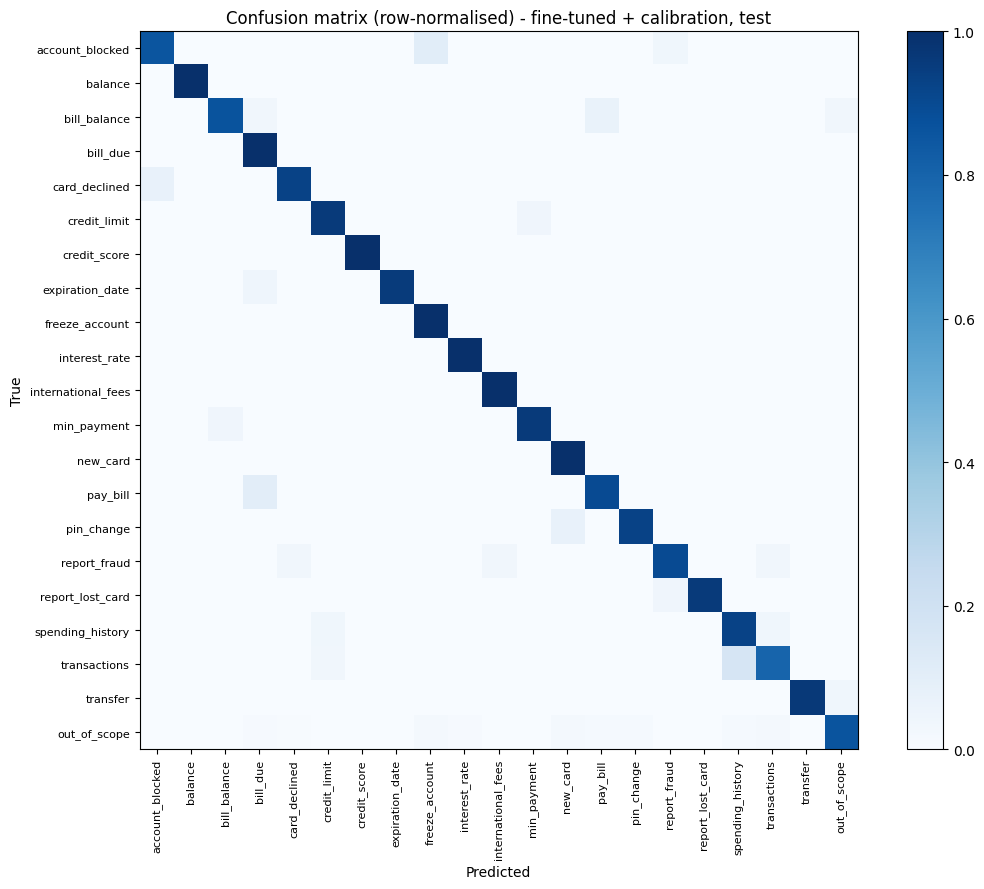

Confusable pairs (count of errors in each direction):
  bill_due -> pay_bill: 0 | pay_bill -> bill_due: 3
  account_blocked -> freeze_account: 3 | freeze_account -> account_blocked: 0
  report_lost_card -> card_declined: 0 | card_declined -> report_lost_card: 0

Top-10 confusions (count, true -> predicted):
    6  out_of_scope -> new_card
    6  out_of_scope -> freeze_account
    5  transactions -> spending_history
    5  out_of_scope -> transactions
    4  out_of_scope -> spending_history
    4  out_of_scope -> pin_change
    4  out_of_scope -> pay_bill
    3  pay_bill -> bill_due
    3  out_of_scope -> interest_rate
    3  out_of_scope -> bill_due


,precision,recall,f1-score,support
transactions,0.774,0.800,0.787,30.0
spending_history,0.743,0.929,0.825,28.0
freeze_account,0.719,1.000,0.836,23.0
new_card,0.742,1.000,0.852,23.0
pay_bill,0.812,0.897,0.852,29.0
account_blocked,0.889,0.857,0.873,28.0
bill_due,0.778,1.000,0.875,28.0
pin_change,0.862,0.926,0.893,27.0
report_fraud,0.929,0.897,0.912,29.0
card_declined,0.897,0.929,0.912,28.0


In [25]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

def extra_metrics(y, probs):
    """AUROC for OOS detection (score = 1 - max known prob) and Top-3 accuracy over the 20 known intents (in-scope only)."""
    known_ids = [i for i in range(probs.shape[1]) if i != oos_id]
    oos_score = 1.0 - probs[:, known_ids].max(axis=1)
    auroc = roc_auc_score((y == oos_id).astype(int), oos_score)
    in_idx = np.where(y != oos_id)[0]
    top3 = np.array(known_ids)[np.argsort(-probs[:, known_ids], axis=1)[:, :3]]
    top3_acc = float(np.mean([y[i] in top3[i] for i in in_idx]))
    return {"auroc_oos": float(auroc), "top3_accuracy_in_scope": top3_acc}

extra_table = pd.DataFrame([{"model": n, **extra_metrics(y, p)} for n, y, p in [
    ("Frozen PhoBERT + calib.", frozen_test_y, frozen_test_probs_cal),
    ("Fine-tuned (raw argmax)", fine_test_y, fine_test_probs_raw),
    ("Fine-tuned + calib.", fine_test_y, fine_test_probs_cal)]])
display(extra_table)
extra_table.to_csv(OUT/"extra_metrics_auroc_top3.csv", index=False)

labels = [id2label[i] for i in range(len(label2id))]
cm = np.array(fine_cal_test_metrics["confusion_matrix"])
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (row-normalised) - fine-tuned + calibration, test")
fig.colorbar(im, fraction=0.046); plt.tight_layout()
fig.savefig(OUT/"confusion_matrix.png", dpi=200); plt.show()

print("Confusable pairs (count of errors in each direction):")
for a, b in [("bill_due", "pay_bill"), ("account_blocked", "freeze_account"), ("report_lost_card", "card_declined")]:
    i, j = label2id[a], label2id[b]
    print(f"  {a} -> {b}: {cm[i, j]} | {b} -> {a}: {cm[j, i]}")

off = sorted([(int(cm[i, j]), labels[i], labels[j]) for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j] > 0], reverse=True)[:10]
print("\nTop-10 confusions (count, true -> predicted):")
for c, t, p in off: print(f"  {c:3d}  {t} -> {p}")

per_class = pd.DataFrame(fine_cal_test_metrics["per_class"]).T.loc[labels, ["precision", "recall", "f1-score", "support"]]
display(per_class.sort_values("f1-score").round(3))
per_class.to_csv(OUT/"per_class_metrics.csv")

### Step A2 - Read the actual mistakes (test set)

Purpose: decide whether errors come from the **model** or from the **data**. For each confusable pair we print the misclassified test sentences and a few random training sentences of both intents. If the sentences of the two intents are nearly interchangeable (ambiguous translation, overlapping meaning, or a label that looks wrong), the fix is in the data/label definition, not the model. Test sentences are only *inspected* here; nothing is tuned on them. The full error list is saved to `misclassified_test.csv`.

In [26]:
# Align predictions with the test sentences (loader order == test_rows order, shuffle=False)
pred_test = threshold_predict(fine_test_probs_cal, fine_threshold_cal, oos_id)
_known = [i for i in range(len(label2id)) if i != oos_id]
max_known = fine_test_probs_cal[:, _known].max(axis=1)
assert len(test_rows) == len(fine_test_y), "test_rows and test labels differ in length"
assert all(label2id[source_label(y)] == int(t) for (_, y), t in zip(test_rows, fine_test_y)), "test_rows order != loader order"

err_all = pd.DataFrame({
    "text": [t for t, _ in test_rows],
    "true": [id2label[int(i)] for i in fine_test_y],
    "pred": [id2label[int(i)] for i in pred_test],
    "max_known_prob": np.round(max_known, 3),
})
err_df = err_all[err_all.true != err_all.pred].reset_index(drop=True)
err_df.to_csv(OUT / "misclassified_test.csv", index=False, encoding="utf-8-sig")
print(f"Errors: {len(err_df)} / {len(err_all)} test sentences (saved to misclassified_test.csv)\n")

_rs = random.Random(0)
def show_errors(true_label, pred_label, n=8):
    sub = err_df[(err_df.true == true_label) & (err_df.pred == pred_label)]
    print(f"=== TRUE {true_label}  ->  PREDICTED {pred_label}   ({len(sub)} errors) ===")
    for _, r in sub.head(n).iterrows():
        print(f"  [{r.max_known_prob:.2f}] {r.text}")
    print()

def show_train_examples(label, n=5):
    pool = [t for t, y in train_rows if y == label]
    print(f"  random TRAIN sentences of `{label}`:")
    for t in _rs.sample(pool, min(n, len(pool))):
        print(f"    - {t}")

# 1) Confusable intent pairs: errors + what each intent looks like in training data
PAIRS = [("transactions", "spending_history"), ("spending_history", "transactions"),
         ("account_blocked", "freeze_account"), ("pay_bill", "bill_due")]
for a, b in PAIRS:
    show_errors(a, b)
for a, b in [("transactions", "spending_history"), ("account_blocked", "freeze_account"), ("pay_bill", "bill_due")]:
    print(f"--- Do `{a}` and `{b}` look different in the training data? ---")
    show_train_examples(a); show_train_examples(b); print()

# 2) OOS sentences wrongly accepted as an in-scope intent (which intents "steal" OOS?)
oos_accepted = err_df[(err_df.true == OOS_LABEL)]
print("OOS wrongly accepted - predicted intent counts:")
print(oos_accepted.pred.value_counts().to_string(), "\n")
for lab in oos_accepted.pred.value_counts().index[:3]:
    show_errors(OOS_LABEL, lab, n=6)

# 3) In-scope sentences wrongly rejected as OOS
rejected = err_df[(err_df.pred == OOS_LABEL) & (err_df.true != OOS_LABEL)]
print(f"=== In-scope sentences REJECTED as out_of_scope ({len(rejected)}) ===")
for _, r in rejected.sort_values("true").iterrows():
    print(f"  [{r.max_known_prob:.2f}] ({r.true}) {r.text}")


Errors: 73 / 818 test sentences (saved to misclassified_test.csv)

=== TRUE transactions  ->  PREDICTED spending_history   (5 errors) ===
  [0.99] mình đã tiêu bao nhiêu tiền trong giao dịch gần nhất
  [0.99] mình đã tiêu tiền vào những khoản nào
  [0.99] cho mình xem mình đã tiêu tiền vào những khoản nào
  [0.99] tháng này tôi đã tiêu bao nhiêu bằng thẻ ghi nợ
  [0.94] từ lần thanh toán hóa đơn gần nhất đến giờ, tôi đã tiêu bao nhiêu bằng thẻ ngân hàng

=== TRUE spending_history  ->  PREDICTED transactions   (1 errors) ===
  [0.80] tình hình tài chính gần đây của tôi thế nào

=== TRUE account_blocked  ->  PREDICTED freeze_account   (3 errors) ===
  [0.54] làm sao để mở khóa tài khoản ngân hàng
  [0.96] bạn có thể mở khóa tài khoản ngân hàng của tôi không
  [0.83] bạn có thể giúp tôi mở khóa tài khoản ngân hàng không

=== TRUE pay_bill  ->  PREDICTED bill_due   (3 errors) ===
  [0.87] hôm nay là ngày mình cần thanh toán hóa đơn tiền điện
  [0.94] hóa đơn tiền điện của tôi đến hạn thanh

### Step B - Augmentation ablation with 3 seeds
Purpose: train (i) frozen baseline, (ii) fine-tuned without augmentation, (iii) fine-tuned with augmentation (no-accent / teencode / typo) for each seed, apply the same temperature scaling + OOS threshold recipe (validation only), and evaluate on the clean test set plus the three noisy test sets. Test data is never used for any choice. Note: seed 42 may differ slightly from the main run above because data-loader shuffling order depends on the RNG state.

In [27]:
import gc, io, contextlib

SEEDS = [42, 43, 44]
AUG_PROB = CFG.augmentation_probability   # try 0.5 for stronger augmentation
RUN_FROZEN_SEEDS = True                   # set False to skip the frozen baseline (saves ~12 min)

def run_experiment(kind, rows_used, seed):
    seed_everything(seed)
    ld = make_loaders(rows_used, val_rows, test_rows)
    frozen = (kind == "frozen")
    model = PhoBERTIntentClassifier(CFG.model_name, len(label2id), freeze_encoder=frozen, dropout=CFG.dropout,
                                    pooling=CFG.frozen_pooling if frozen else "cls").to(CFG.device)
    epochs, lr = (CFG.frozen_epochs, CFG.frozen_learning_rate) if frozen else (CFG.epochs, CFG.learning_rate)
    with contextlib.redirect_stdout(io.StringIO()):
        model, _ = train_torch_model(model, ld, epochs, lr)
    val_logits, val_y = predict_loader(model, ld["val"])
    test_logits, test_y = predict_loader(model, ld["test"])
    temperature, _ = fit_temperature(val_logits, val_y, CFG.temperature_min, CFG.temperature_max, CFG.temperature_steps)
    threshold = tune_oos_threshold(softmax_np(val_logits, temperature), val_y, grid)["threshold"]
    test_probs = softmax_np(test_logits, temperature)
    row = {k: v for k, v in classification_metrics(test_y, test_probs, threshold).items() if isinstance(v, float)}
    row.update(extra_metrics(test_y, test_probs))
    for name, noisy in robustness_sets.items():
        if name == "clean": continue
        combined = noisy + [[normalize_model_text(t), OOS_LABEL] for t, _ in oos_test]
        row[f"macro_f1_{name}"] = evaluate_rows_with_model(model, combined, temperature, threshold)["macro_f1_21_labels"]
    row.update({"temperature": temperature, "threshold": threshold})
    del model; gc.collect(); torch.cuda.empty_cache()
    return row

experiments = []
if RUN_FROZEN_SEEDS: experiments.append(("frozen_baseline", "frozen", lambda s: train_rows))
experiments += [("finetune_no_aug", "finetune", lambda s: train_rows),
                ("finetune_aug", "finetune", lambda s: augment_training_rows(train_rows, AUG_PROB, s))]

seed_rows = []
for exp_name, exp_kind, rows_fn in experiments:
    for exp_seed in SEEDS:
        row = run_experiment(exp_kind, rows_fn(exp_seed), exp_seed)
        row.update({"experiment": exp_name, "seed": exp_seed})
        seed_rows.append(row)
        print(f"{exp_name} seed={exp_seed}: macro_f1={row['macro_f1_21_labels']:.3f} oos_f1={row['oos_f1']:.3f} no_accent_f1={row['macro_f1_no_accent']:.3f}")
seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv(OUT/"seed_ablation_runs.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


frozen_baseline seed=42: macro_f1=0.841 oos_f1=0.849 no_accent_f1=0.183


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


frozen_baseline seed=43: macro_f1=0.837 oos_f1=0.838 no_accent_f1=0.205


... (17 outputs left out)

finetune_aug seed=43: macro_f1=0.903 oos_f1=0.898 no_accent_f1=0.762


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


finetune_aug seed=44: macro_f1=0.930 oos_f1=0.927 no_accent_f1=0.750


### Step C - Mean +/- std summary (**headline table for the report**)

Single-seed numbers vary by roughly 1-2 points between runs, so report this 3-seed table, not the seed-42 table in Step 20. `finetune_aug` is the proposed model (same recipe as the main `fine_model`).

In [28]:
cols = ["in_scope_accuracy", "macro_f1_21_labels", "oos_f1", "fpr_at_95_tpr", "auroc_oos", "top3_accuracy_in_scope", "ece",
        "macro_f1_no_accent", "macro_f1_teencode", "macro_f1_typo"]
grp = seed_df.groupby("experiment", sort=False)[cols].agg(["mean", "std"])
summary_seeds = pd.DataFrame({c: grp[c]["mean"].map("{:.3f}".format) + " +/- " + grp[c]["std"].fillna(0).map("{:.3f}".format) for c in cols})
display(summary_seeds)
summary_seeds.to_csv(OUT/"seed_ablation_summary.csv")

# ---- Headline table: readable names + number of seeds ----
NAME_MAP = {
    "frozen_baseline": "Frozen PhoBERT + calibration (baseline)",
    "finetune_no_aug": "Fine-tuned PhoBERT, no augmentation",
    "finetune_aug":    "Fine-tuned PhoBERT + augmentation (proposed)",
}
main_table = summary_seeds.rename(index=NAME_MAP)
main_table.insert(0, "n_seeds", seed_df.groupby("experiment", sort=False).size().values)
main_table.index.name = "model"
display(main_table)
main_table.to_csv(OUT/"main_results_3seeds.csv")
print("Seeds:", SEEDS, "| values are mean +/- sample std (n=3, so treat std as a rough guide).")


,in_scope_accuracy,macro_f1_21_labels,oos_f1,fpr_at_95_tpr,auroc_oos,top3_accuracy_in_scope,ece,macro_f1_no_accent,macro_f1_teencode,macro_f1_typo
experiment,,,,,,,,,,
frozen_baseline,0.894 +/- 0.000,0.842 +/- 0.005,0.849 +/- 0.010,0.085 +/- 0.004,0.981 +/- 0.000,0.963 +/- 0.002,0.034 +/- 0.003,0.197 +/- 0.012,0.845 +/- 0.006,0.823 +/- 0.006
finetune_no_aug,0.932 +/- 0.006,0.921 +/- 0.011,0.936 +/- 0.016,0.045 +/- 0.020,0.987 +/- 0.000,0.989 +/- 0.003,0.034 +/- 0.012,0.189 +/- 0.046,0.914 +/- 0.012,0.907 +/- 0.005
finetune_aug,0.934 +/- 0.011,0.915 +/- 0.014,0.916 +/- 0.016,0.055 +/- 0.003,0.986 +/- 0.001,0.988 +/- 0.004,0.035 +/- 0.003,0.770 +/- 0.025,0.912 +/- 0.013,0.908 +/- 0.014


,n_seeds,in_scope_accuracy,macro_f1_21_labels,oos_f1,fpr_at_95_tpr,auroc_oos,top3_accuracy_in_scope,ece,macro_f1_no_accent,macro_f1_teencode,macro_f1_typo
model,,,,,,,,,,,
Frozen PhoBERT + calibration (baseline),3,0.894 +/- 0.000,0.842 +/- 0.005,0.849 +/- 0.010,0.085 +/- 0.004,0.981 +/- 0.000,0.963 +/- 0.002,0.034 +/- 0.003,0.197 +/- 0.012,0.845 +/- 0.006,0.823 +/- 0.006
"Fine-tuned PhoBERT, no augmentation",3,0.932 +/- 0.006,0.921 +/- 0.011,0.936 +/- 0.016,0.045 +/- 0.020,0.987 +/- 0.000,0.989 +/- 0.003,0.034 +/- 0.012,0.189 +/- 0.046,0.914 +/- 0.012,0.907 +/- 0.005
Fine-tuned PhoBERT + augmentation (proposed),3,0.934 +/- 0.011,0.915 +/- 0.014,0.916 +/- 0.016,0.055 +/- 0.003,0.986 +/- 0.001,0.988 +/- 0.004,0.035 +/- 0.003,0.770 +/- 0.025,0.912 +/- 0.013,0.908 +/- 0.014


Seeds: [42, 43, 44] | values are mean +/- sample std (n=3, so treat std as a rough guide).


## Section 12 — Model Artifacts Export & Latency Measurement
### Step 23 — Save model, tokenizer, calibration, schema, and experiment metadata

Purpose: produce a self-contained inference artifact. The exported configuration records the label mapping, threshold, temperature, preprocessing assumptions, and model identity needed to reproduce predictions.

In [29]:
ARTIFACT_DIR=OUT/"final_phobert"
ARTIFACT_DIR.mkdir(parents=True,exist_ok=True)
torch.save(fine_model.state_dict(),ARTIFACT_DIR/"model_state.pt")
TOKENIZER.save_pretrained(ARTIFACT_DIR/"tokenizer")
with (ARTIFACT_DIR/"metadata.json").open("w",encoding="utf-8") as f:
    json.dump({
        "model_name":CFG.model_name,
        "max_length":CFG.max_length,
        "label2id":label2id,
        "id2label":{str(k):v for k,v in id2label.items()},
        "oos_id":oos_id,
        "temperature":fine_temperature,
        "oos_threshold":fine_threshold_cal,
        "preprocessing":"Unicode NFC + whitespace normalization + underthesea word segmentation",
        "seed":CFG.seed,
        "train_augmentation":CFG.use_train_augmentation,
        "augmentation_probability":CFG.augmentation_probability,
    },f,ensure_ascii=False,indent=2)

# Also persist evaluation artifacts.
with (OUT/"final_metrics.json").open("w",encoding="utf-8") as f:
    json.dump({
        "frozen_phobert_uncalibrated":frozen_metrics,
        "frozen_phobert_calibrated":frozen_cal_test_metrics,
        "fine_tuned_phobert_raw":fine_raw_test_metrics,
        "fine_tuned_phobert_calibrated":fine_cal_test_metrics,
        "robustness":robust_results,
        "seed_runs":(seed_df.to_dict(orient="records") if "seed_df" in globals() else None),
    },f,ensure_ascii=False,indent=2,default=lambda x:x.tolist() if isinstance(x,np.ndarray) else x)
print("Artifacts exported to:",ARTIFACT_DIR)

Artifacts exported to: artifacts_notebook/final_phobert


### Step 24 — Measure inference latency and produce final experiment manifest

Purpose: quantify deployment cost and create a final manifest linking the dataset audit, model checkpoint, calibration parameters, robustness results, and latency. Latency is measured after a short warm-up and excludes model loading time; the exact hardware/device is recorded.

In [30]:
@torch.no_grad()
def predict_one(text):
    fine_model.eval()
    segmented=segment_vietnamese(text)
    enc=TOKENIZER(segmented,truncation=True,max_length=CFG.max_length,return_tensors="pt")
    enc={k:v.to(CFG.device) for k,v in enc.items()}
    logits=fine_model(input_ids=enc["input_ids"],attention_mask=enc["attention_mask"],token_type_ids=enc.get("token_type_ids"))
    probs=torch.softmax(logits/fine_temperature,dim=-1)[0].cpu().numpy()
    known=[i for i in range(len(label2id)) if i!=oos_id]
    best=max(known,key=lambda i:probs[i])
    max_known=float(probs[best])
    pred=oos_id if max_known<fine_threshold_cal else best
    return {"input":text,"predicted_label":id2label[pred],"confidence":float(probs[pred]),"max_known_probability":max_known}

sample_texts=[t for t,_ in clean_data["test"][:20]]
# Warm-up.
for text in sample_texts[:5]: _=predict_one(text)
if CFG.device.startswith("cuda"): torch.cuda.synchronize()
start=time.perf_counter()
for text in sample_texts:
    _=predict_one(text)
if CFG.device.startswith("cuda"): torch.cuda.synchronize()
elapsed=time.perf_counter()-start
latency={
    "device":CFG.device,
    "hardware":torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor(),
    "examples_measured":len(sample_texts),
    "total_seconds":elapsed,
    "milliseconds_per_example":elapsed/max(len(sample_texts),1)*1000,
}
with (OUT/"latency.json").open("w",encoding="utf-8") as f: json.dump(latency,f,indent=2)

manifest={
    "pipeline":"TMG Vietnamese Intent Classification",
    "classes":len(label2id),
    "train_size":len(train_rows),"val_size":len(val_rows),"test_size":len(test_rows),
    "threshold":fine_threshold_cal,"temperature":fine_temperature,"train_augmentation":CFG.use_train_augmentation,
    "latency":latency,
    "artifact_dir":str(ARTIFACT_DIR),
    "dataset_audits":["dataset_counts_raw.csv","exact_duplicate_audit.csv","deduplication_audit.csv","cross_split_leakage_after_dedup.csv","near_duplicate_audit.csv"],
    "frozen_baseline":{"pooling":CFG.frozen_pooling,"epochs":CFG.frozen_epochs,"temperature":frozen_temperature,"threshold":frozen_threshold_cal},
    "models":["Frozen PhoBERT + classifier","Fine-tuned PhoBERT + temperature scaling + OOS threshold"],
}
with (OUT/"experiment_manifest.json").open("w",encoding="utf-8") as f: json.dump(manifest,f,ensure_ascii=False,indent=2)

print(json.dumps(manifest,ensure_ascii=False,indent=2))
print("\nExample inference:")
print(predict_one("mình muốn kiểm tra số dư tài khoản"))

{
  "pipeline": "TMG Vietnamese Intent Classification",
  "classes": 21,
  "train_size": 1932,
  "val_size": 481,
  "test_size": 818,
  "threshold": 0.445,
  "temperature": 0.575,
  "train_augmentation": true,
  "latency": {
    "device": "cuda",
    "hardware": "Tesla T4",
    "examples_measured": 20,
    "total_seconds": 0.22786479799992776,
    "milliseconds_per_example": 11.393239899996388
  },
  "artifact_dir": "artifacts_notebook/final_phobert",
  "dataset_audits": [
    "dataset_counts_raw.csv",
    "exact_duplicate_audit.csv",
    "deduplication_audit.csv",
    "cross_split_leakage_after_dedup.csv",
    "near_duplicate_audit.csv"
  ],
  "frozen_baseline": {
    "pooling": "mean",
    "epochs": 12,
    "temperature": 0.42500000000000004,
    "threshold": 0.22500000000000003
  },
  "models": [
    "Frozen PhoBERT + classifier",
    "Fine-tuned PhoBERT + temperature scaling + OOS threshold"
  ]
}

Example inference:
{'input': 'mình muốn kiểm tra số dư tài khoản', 'predicted_label'

## Final Research Protocol Check

The notebook now follows the 24-step workflow while preserving the project's methodological constraints:

- **Data:** 20 supported intents + `out_of_scope`.
- **Leakage:** exact normalization audit, deduplication, cross-split assertion, and near-duplicate audit.
- **Baseline:** frozen PhoBERT (eval mode, mean pooling) + simple classifier, with the same temperature scaling and OOS threshold recipe as the proposed model.
- **Proposed model:** fine-tuned PhoBERT.
- **OOS:** explicit OOS class plus validation-only confidence rejection threshold.
- **Calibration:** validation-only temperature scaling.
- **Ablations:** class-weighting and realistic Vietnamese noise augmentation are defined as controlled variants.
- **Robustness:** clean, no-accent, teencode, and typo conditions.
- **Metrics:** Macro-F1, in-scope accuracy, overall accuracy, OOS precision/recall/F1, FPR@95TPR, ECE, per-class metrics, and confusion matrix.
- **Deployment evidence:** checkpoint, tokenizer, label mapping, calibration parameters, experiment manifest, and latency.

No experimental score should be interpreted as a project result until this notebook has been executed against the finalized dataset and the resulting artifacts have been inspected.

### Step 25 — Web app DEMO

In [31]:
import gradio as gr
import numpy as np
import torch


def gradio_predict(text, top_k, oos_threshold):
    if not text or not text.strip():
        return (
            "⚠️ Vui lòng nhập câu cần phân loại.",
            "",
            "",
            ""
        )

    try:
        fine_model.eval()

        segmented = segment_vietnamese(text)

        enc = TOKENIZER(
            segmented,
            truncation=True,
            max_length=CFG.max_length,
            return_tensors="pt"
        )

        enc = {
            k: v.to(CFG.device)
            for k, v in enc.items()
        }

        with torch.no_grad():
            logits = fine_model(
                input_ids=enc["input_ids"],
                attention_mask=enc["attention_mask"],
                token_type_ids=enc.get("token_type_ids")
            )

        # Temperature scaling
        probs = torch.softmax(
            logits / fine_temperature,
            dim=-1
        )[0].cpu().numpy()

        top_k = int(top_k)

        top_indices = np.argsort(probs)[::-1][:top_k]

        top_k_text = "\n".join(
            f"{rank}. `{id2label[int(idx)]}` — "
            f"**{probs[idx] * 100:.2f}%**"
            for rank, idx in enumerate(top_indices, 1)
        )


        known_ids = [
            i for i in range(len(label2id))
            if i != oos_id
        ]

        best_known = max(
            known_ids,
            key=lambda i: probs[i]
        )

        max_known_probability = float(
            probs[best_known]
        )

        if max_known_probability < float(oos_threshold):
            predicted_id = oos_id
            is_oos = True
        else:
            predicted_id = best_known
            is_oos = False

        predicted_intent = id2label[predicted_id]
        confidence = float(probs[predicted_id])

        # Result display
        if is_oos:
            intent_output = (
                f"⚠️ OUT OF SCOPE\n\n"
                f"**Intent:** `{predicted_intent}`"
            )

            warning_output = (
                f"⚠️ **Cảnh báo OOS:** câu nhập vào có "
                f"xác suất cao nhất trong các intent hỗ trợ "
                f"chỉ là **{max_known_probability * 100:.2f}%**, "
                f"thấp hơn ngưỡng **{float(oos_threshold) * 100:.2f}%**."
            )

        else:
            intent_output = (
                f"### Predicted Intent\n\n"
                f"**`{predicted_intent}`**"
            )

            warning_output = (
                "✅ Câu hỏi nằm trong phạm vi "
                "các intent được hỗ trợ."
            )

        confidence_output = (
            f"### Confidence\n\n"
            f"**{confidence * 100:.2f}%**"
        )

        return (
            intent_output,
            confidence_output,
            top_k_text,
            warning_output
        )

    except Exception as e:
        return (
            "❌ Prediction Error",
            "",
            "",
            f"```text\n{type(e).__name__}: {e}\n```"
        )


# ============================================================
# GRADIO UI
# ============================================================

with gr.Blocks(
    title="Vietnamese Banking Intent Classification"
) as demo:

    gr.Markdown(
        """
        # Vietnamese Banking Intent Classification

        **PhoBERT + Temperature Scaling + OOS Detection**

        Nhập một câu hỏi/yêu cầu bằng tiếng Việt để hệ thống
        dự đoán **Banking Intent**.
        """
    )

    with gr.Row():

        # ====================================================
        # LEFT — INPUT
        # ====================================================
        with gr.Column(scale=1):

            gr.Markdown("## Input")

            input_text = gr.Textbox(
                label="Câu hỏi / Yêu cầu",
                placeholder=(
                    "Ví dụ: Hạn mức thẻ tín dụng của tôi là bao nhiêu?"
                ),
                lines=5
            )

            top_k = gr.Slider(
                minimum=1,
                maximum=10,
                value=5,
                step=1,
                label="Top-K"
            )

            oos_threshold = gr.Slider(
                minimum=0.05,
                maximum=0.95,
                value=float(fine_threshold_cal),
                step=0.01,
                label="OOS Threshold",
                info=(
                    "Ngưỡng được tối ưu trên validation set; "
                    "có thể điều chỉnh để demo."
                )
            )

            predict_btn = gr.Button(
                "Dự đoán / Tra cứu",
                variant="primary"
            )

            gr.Markdown("### Ví dụ")

            gr.Examples(
                examples=[
                    ["Hạn mức thẻ tín dụng của tôi là bao nhiêu?"],
                    ["Tôi muốn khóa thẻ gấp"],
                    ["Tôi muốn kiểm tra số dư tài khoản"],
                    ["Tôi muốn đổi mã PIN"],
                    ["Tôi muốn báo giao dịch gian lận"],
                    ["Thời tiết hôm nay thế nào?"],
                ],
                inputs=input_text,
            )

        # ====================================================
        # RIGHT — OUTPUT
        # ====================================================
        with gr.Column(scale=1):

            gr.Markdown("## Prediction")

            intent_output = gr.Markdown(
                "Chưa có kết quả."
            )

            confidence_output = gr.Markdown()

            gr.Markdown("### Top-K Intents")

            top_k_output = gr.Markdown()

            warning_output = gr.Markdown()


    # --------------------------------------------------------
    # Button event
    # --------------------------------------------------------
    predict_btn.click(
        fn=gradio_predict,
        inputs=[
            input_text,
            top_k,
            oos_threshold
        ],
        outputs=[
            intent_output,
            confidence_output,
            top_k_output,
            warning_output
        ]
    )

In [32]:
demo.launch(inline=True, share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c080db373d3bce155a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
